# 06 - Cross-Validation, Calibration and Model Stability (Phase 5)
**Questions**
1. Are the three leading models (logistic regression, gradient boosting, random forest) stable under cross-validation?
2. How well calibrated are their probabilities?
3. Does recalibration (sigmoid / isotonic) materially improve probability quality?
4. Is logistic regression with categorical counts still a defensible *provisional* choice?
5. Are there meaningful differences in probability quality between the models?

## Data policy (enforced in code)
| Split | Phase 5 use |
|---|---|
| TRAIN (`train.csv`, 6,938) | **all** cross-validation, out-of-fold (OOF) predictions, calibration analysis and calibrator fitting |
| VALIDATION (`validation.csv`, 1,487) | one controlled **confirmation** at the end (Part 7); not used for CV folds, not used to tune anything here |
| TEST (`test.csv`) | **off limits.** An audit hook *raises an error the moment any process-level `open()` touches a file named `test.csv`* (raw or processed), and the notebook ends by printing every data file opened and asserting the test set was never accessed. |

*Disclosure (carried over from earlier phases):* the Phase 2-3 EDA/statistics used all modelling rows to describe associations and no model was fitted or scored on test rows. The Phase 4 hyper-parameters were chosen on the validation split, so training-CV estimates for those configurations are not independent of validation.

## Models and why the decision tree is omitted
Leading configurations are taken **unchanged from Phase 4** by cloning the saved pipelines (`models/phase4/*.joblib`), so preprocessing and hyper-parameters are exactly those of Phase 4:
**LR_B** (logistic regression, categorical counts, C = 1), **GB_B** (gradient boosting, 300 trees, learning rate 0.05, depth 2) and **RF_B** (random forest, 300 trees, depth 10, min leaf 10, sqrt features).
The decision tree is excluded from the detailed analysis because Phase 4 showed it is clearly weaker (validation log loss 0.48-0.50 vs 0.44, with a paired CI excluding 0) and its probabilities take only a few coarse values, so it is not a candidate for the final probability model.

In [1]:
import warnings
warnings.simplefilter("always")
import os, sys, json, time
from pathlib import Path

# ---- TEST-SET AUDIT HOOK: record every file open; RAISE immediately if a file named test.csv is opened ----
_OPENED = []
def _audit(event, args):
    if event == "open" and args and isinstance(args[0], (str, bytes, os.PathLike)):
        p = os.fsdecode(args[0]); _OPENED.append(p)
        if os.path.basename(p).lower() == "test.csv":
            raise PermissionError(f"PHASE 5 VIOLATION: attempt to open {p} (the test set is off limits)")
sys.addaudithook(_audit)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn
import statsmodels.api as sm
from scipy import stats
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, log_loss, brier_score_loss)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, MODELS = ROOT / "data" / "processed", ROOT / "models" / "phase4"
MET, FIG = ROOT / "results" / "metrics" / "modeling", ROOT / "results" / "figures" / "modeling"
MET.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

SEED, K, B_BOOT, NB = 42, 5, 1000, 10          # random seed, CV folds, bootstrap resamples, calibration bins
EPS = 1e-6                                       # clipping for logit(p)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60); pd.set_option("display.max_colwidth", 90)
sns.set_theme(style="whitegrid", rc={"grid.color": "#e3e6ea", "axes.edgecolor": "#9aa3ad", "axes.titlesize": 12,
                                      "axes.titleweight": "semibold", "axes.labelsize": 10.5, "figure.dpi": 110})
PLACED_C, NOT_C, NEUTRAL = "#2166ac", "#e08214", "#6b7785"
MODEL_IDS = ["LR_B", "GB_B", "RF_B"]
LABEL = {"LR_B": "Logistic regression (B)", "GB_B": "Gradient boosting (B)", "RF_B": "Random forest (B)"}
COL = {"LR_B": "#0072B2", "GB_B": "#D55E00", "RF_B": "#009E73"}             # same family colours as Phase 4
METH_C = {"original": "#1d2733", "sigmoid": "#E69F00", "isotonic": "#CC79A7"}
def savefig(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight"); plt.show()
def write_json(obj, path):
    with open(path, "w", encoding="utf-8") as fh: json.dump(obj, fh, indent=2, default=str)
print("scikit-learn", sklearn.__version__, "| seed", SEED, "| folds", K)

scikit-learn 1.9.1 | seed 42 | folds 5


## 1. Load TRAIN and VALIDATION only; clone the exact Phase 4 pipelines

In [2]:
TARGET = "PlacementStatus"
FEATURES = ["CGPA", "Internships", "Projects", "Workshops/Certifications", "AptitudeTestScore", "SoftSkillsRating",
            "ExtracurricularActivities", "PlacementTraining", "SSC_Marks", "HSC_Marks"]
COUNT = ["Internships", "Projects", "Workshops/Certifications"]
train = pd.read_csv(PROC / "train.csv"); val = pd.read_csv(PROC / "validation.csv")
for d in (train, val):
    assert d.isna().sum().sum() == 0 and set(d[TARGET]) == {"Placed", "NotPlaced"}
assert not (set(map(tuple, train[FEATURES].values)) & set(map(tuple, val[FEATURES].values)))
X_tr, X_va = train[FEATURES].copy(), val[FEATURES].copy()
y_tr = (train[TARGET] == "Placed").astype(int).to_numpy(); y_va = (val[TARGET] == "Placed").astype(int).to_numpy()
for c in COUNT: X_tr[c] = X_tr[c].astype(int); X_va[c] = X_va[c].astype(int)
train_row_id = np.arange(len(train))                 # stable id = 0-based row position in train.csv (dataset untouched)
print(f"train {X_tr.shape} (Placed {y_tr.mean():.4f}) | validation {X_va.shape} (Placed {y_va.mean():.4f})")

with open(MODELS / "model_configs.json", encoding="utf-8") as fh: P4 = json.load(fh)
BASE = {m: clone(joblib.load(MODELS / f"{m}.joblib")) for m in MODEL_IDS}      # UNFITTED clones with identical Phase 4 parameters
for m in MODEL_IDS:
    assert not hasattr(BASE[m].named_steps["model"], "classes_")
    print(f"{m}: {P4['models'][m]['config']}")
with open(MET / "05_provisional_selection.json", encoding="utf-8") as fh: print("\nPhase 4 provisional selection:", json.load(fh)["provisional_model_id"])

train (6938, 10) (Placed 0.4155) | validation (1487, 10) (Placed 0.4156)


LR_B: {'C': 1.0, 'class_weight': None}
GB_B: {'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 1}
RF_B: {'n_estimators': 300, 'max_depth': 10, 'min_samples_leaf': 10, 'max_features': 'sqrt'}

Phase 4 provisional selection: LR_B


## 2. Metric helpers
- **ROC-AUC, log loss, Brier score:** primary measures of ranking and probability quality. Accuracy/precision/recall/F1 (threshold 0.5, **not tuned**) are secondary.
- **Calibration intercept and slope** (Cox / logistic recalibration): fit the unpenalised logistic regression `logit P(Placed) = a + b * logit(p_hat)` on out-of-sample predictions.
  *Slope* **b**: 1 is ideal; **b < 1** means predictions are too extreme (over-dispersed: high probabilities too high and low ones too low, the usual signature of over-fitting); **b > 1** means predictions are too timid (under-dispersed). *Intercept* **a** (with slope estimated jointly) is hard to read alone because it depends on the slope, so the **calibration-in-the-large (CITL)** is also reported: the intercept when the slope is fixed at 1 (an offset model); CITL = 0 means the average predicted risk matches the observed rate, > 0 means the model under-predicts placement on average, < 0 over-predicts. These are summaries to interpret *in context* with the reliability curve, not mechanical pass/fail tests.
- **Expected calibration error (ECE):** `sum_b (n_b / N) * |mean predicted_b - observed rate_b|`. ECE depends on binning, so the primary version uses **10 equal-count (quantile) bins** (ties broken by stable sort), and an equal-width 10-bin version (empty bins skipped) is shown as a sensitivity check. ECE is supplementary; log loss, Brier and the slope/intercept are the primary calibration evidence.
- **ECE yardstick:** because a finite sample never gives ECE = 0, each ECE is shown next to `ece_q_null_mean` / `ece_q_null_p95`: the mean and 95th percentile of ECE obtained by simulating outcomes from the model's own probabilities (i.e. *perfect* calibration plus sampling noise only; 1,000 simulations). An observed ECE at or below the null 95th percentile is statistically unremarkable.
- **Reliability bins:** 10 equal-count bins, so every bin holds about N/10 observations (about 690 for the training OOF set, about 150 for validation) and no bin is tiny; Wilson 95% intervals show the sampling noise.

In [3]:
logit = lambda p: np.log(np.clip(p, EPS, 1 - EPS) / (1 - np.clip(p, EPS, 1 - EPS)))

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n; c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

def quantile_bins(p, y, nb=NB):
    order = np.argsort(p, kind="mergesort"); rows = []
    for i, ch in enumerate(np.array_split(order, nb)):
        k, n = int(y[ch].sum()), len(ch); lo, hi = wilson(k, n)
        rows.append({"bin": i + 1, "n": n, "p_min": p[ch].min(), "p_max": p[ch].max(), "mean_pred": p[ch].mean(), "obs_rate": k / n,
                     "calibration_gap": p[ch].mean() - k / n, "ci_lo": lo, "ci_hi": hi})     # gap = mean predicted - observed (>0: over-prediction)
    return pd.DataFrame(rows)

def ece_quantile(p, y, nb=NB):
    b = quantile_bins(p, y, nb); return float((b.n / b.n.sum() * (b.mean_pred - b.obs_rate).abs()).sum())

def ece_uniform(p, y, nb=NB):
    idx = np.minimum((p * nb).astype(int), nb - 1); tot = 0.0
    for b in range(nb):
        m = idx == b
        if m.any(): tot += m.mean() * abs(p[m].mean() - y[m].mean())
    return float(tot)

def ece_null_summary(p, B=1000, seed=SEED):
    # ECE expected from sampling noise ALONE if the predicted probabilities were perfectly calibrated:
    # simulate outcomes y ~ Bernoulli(p) and recompute the equal-count-bin ECE (bins fixed by p). Gives ECE a yardstick.
    rng = np.random.default_rng(seed); chunks = np.array_split(np.argsort(p, kind="mergesort"), NB); N = len(p)
    mp = [p[c].mean() for c in chunks]; out = np.empty(B)
    for b in range(B):
        yb = (rng.random(N) < p).astype(int)
        out[b] = sum(len(c) / N * abs(m_ - yb[c].mean()) for c, m_ in zip(chunks, mp))
    return {"ece_q_null_mean": float(out.mean()), "ece_q_null_p95": float(np.percentile(out, 95))}

def cal_metrics(p, y):
    z = logit(p); n = len(y)
    citl = sm.GLM(y, np.ones((n, 1)), family=sm.families.Binomial(), offset=z).fit()
    joint = sm.Logit(y, sm.add_constant(z)).fit(disp=0)
    ci_c, ci_j = citl.conf_int(), joint.conf_int()
    return {"roc_auc": roc_auc_score(y, p), "log_loss": log_loss(y, p, labels=[0, 1]), "brier": brier_score_loss(y, p),
            "citl": float(citl.params[0]), "citl_ci_lo": float(ci_c[0][0]), "citl_ci_hi": float(ci_c[0][1]),
            "cal_intercept": float(joint.params[0]), "cal_slope": float(joint.params[1]), "slope_ci_lo": float(ci_j[1][0]), "slope_ci_hi": float(ci_j[1][1]),
            "ece_quantile": ece_quantile(p, y), "ece_uniform": ece_uniform(p, y), **ece_null_summary(p),
            "mean_pred": float(p.mean()), "obs_rate": float(y.mean())}

def clf_metrics(p, y, thr=0.5):
    pred = (p >= thr).astype(int)
    return {"roc_auc": roc_auc_score(y, p), "log_loss": log_loss(y, p, labels=[0, 1]), "brier": brier_score_loss(y, p), "accuracy": accuracy_score(y, pred),
            "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred, zero_division=0), "f1": f1_score(y, pred, zero_division=0)}

## 3. Part 1-2: 5-fold stratified cross-validation and out-of-fold predictions (TRAIN only)
`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`. For each fold, the **whole Phase 4 pipeline** (preprocessing + model) is cloned and fitted on the fold's training portion only, then predicts the held-out fold. Concatenating the held-out predictions gives **one out-of-fold probability per training student, from a model that never saw that student**; all calibration diagnostics use these OOF probabilities.
Each fold model is trained on 80% of the training data (about 5,550 students), so OOF probabilities are from slightly less-trained models than the full-train models of Phase 4.

In [4]:
outer = list(StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED).split(X_tr, y_tr))
fold_of = np.empty(len(y_tr), int)
for k, (_, te) in enumerate(outer, 1): fold_of[te] = k
assert sorted(np.concatenate([te for _, te in outer])) == list(range(len(y_tr)))      # every training row held out exactly once
assert all(not (set(tr) & set(te)) for tr, te in outer)                                # no student is in both the fitting and the held-out part of any fold

OOF = {m: np.full(len(y_tr), np.nan) for m in MODEL_IDS}; fold_rows = []
t0 = time.time()
for k, (tr, te) in enumerate(outer, 1):
    for m in MODEL_IDS:
        pipe = clone(BASE[m]).fit(X_tr.iloc[tr], y_tr[tr])
        p = pipe.predict_proba(X_tr.iloc[te])[:, 1]; OOF[m][te] = p
        fold_rows.append({"model_id": m, "model": LABEL[m], "fold": k, "n_train": len(tr), "n_heldout": len(te), "heldout_placed_rate": y_tr[te].mean(), **clf_metrics(p, y_tr[te])})
assert all(not np.isnan(OOF[m]).any() for m in MODEL_IDS)
folds = pd.DataFrame(fold_rows); folds.to_csv(MET / "06_cv_fold_results.csv", index=False)
print(f"CV complete in {time.time() - t0:.0f}s; folds:", dict(zip(*np.unique(fold_of, return_counts=True))))

METRICS = ["roc_auc", "log_loss", "brier", "accuracy", "precision", "recall", "f1"]
summ = (folds.melt(id_vars=["model_id", "model", "fold"], value_vars=METRICS, var_name="metric")
        .groupby(["model_id", "model", "metric"], sort=False).value.agg(mean="mean", sd="std", min="min", max="max").reset_index())
summ["tier"] = np.where(summ.metric.isin(["roc_auc", "log_loss", "brier"]), "primary", "secondary")
summ.to_csv(MET / "06_cv_summary.csv", index=False)
wide = summ.pivot(index="metric", columns="model_id", values=["mean", "sd", "min", "max"]).reindex(METRICS)
print("5-fold CV on TRAIN (mean / sd / min / max across folds):")
display(wide.round(4))

CV complete in 35s; folds: {np.int64(1): np.int64(1388), np.int64(2): np.int64(1388), np.int64(3): np.int64(1388), np.int64(4): np.int64(1387), np.int64(5): np.int64(1387)}
5-fold CV on TRAIN (mean / sd / min / max across folds):


mean                      sd                     min                     max                
model_id     GB_B    LR_B    RF_B    GB_B    LR_B    RF_B    GB_B    LR_B    RF_B    GB_B    LR_B    RF_B
metric                                                                                                   
roc_auc    0.8761  0.8790  0.8764  0.0114  0.0095  0.0103  0.8629  0.8683  0.8654  0.8890  0.8895  0.8891
log_loss   0.4345  0.4309  0.4331  0.0196  0.0157  0.0154  0.4131  0.4140  0.4146  0.4580  0.4485  0.4497
brier      0.1407  0.1392  0.1400  0.0077  0.0059  0.0056  0.1324  0.1330  0.1333  0.1506  0.1464  0.1457
accuracy   0.7958  0.7985  0.7948  0.0164  0.0103  0.0130  0.7714  0.7866  0.7808  0.8127  0.8112  0.8076
precision  0.7640  0.7599  0.7676  0.0190  0.0121  0.0177  0.7376  0.7473  0.7464  0.7853  0.7749  0.7884
recall     0.7357  0.7530  0.7260  0.0247  0.0140  0.0174  0.6979  0.7344  0.6997  0.7660  0.7695  0.7452
f1         0.7495  0.7564  0.7462  0.0213  0.0128  0.0162  0.7172  0.7408  0.7261  0.7727  0.7722  0.7631

In [5]:
oof_df = pd.DataFrame({"train_row_id": train_row_id, "actual_target": y_tr, "logistic_probability": OOF["LR_B"],
                       "gradient_boosting_probability": OOF["GB_B"], "random_forest_probability": OOF["RF_B"], "fold": fold_of})
# OOF integrity: one row per training student, one fold each, no missing/out-of-range probabilities, and (with the disjoint-fold assertion
# above) each probability comes from a model whose fitting rows exclude that student
assert len(oof_df) == len(train) and oof_df.train_row_id.is_unique and set(oof_df.train_row_id) == set(range(len(train)))
assert oof_df.fold.between(1, K).all() and oof_df.fold.notna().all() and (oof_df.actual_target.to_numpy() == y_tr).all()
assert oof_df[["logistic_probability", "gradient_boosting_probability", "random_forest_probability"]].apply(lambda s: s.between(0, 1).all()).all()
assert not oof_df.isna().any().any()
oof_df.to_csv(MET / "06_oof_predictions.csv", index=False)
print("Saved OOF predictions:", oof_df.shape, "- integrity checks passed (each student exactly once, never scored by a model fitted on them)")
# sanity: OOF metrics on all training rows
pd.DataFrame({m: clf_metrics(OOF[m], y_tr) for m in MODEL_IDS}).T.round(4)

Saved OOF predictions:

 (6938, 6) - integrity checks passed (each student exactly once, never scored by a model fitted on them)


,roc_auc,log_loss,brier,accuracy,precision,recall,f1
LR_B,0.8790,0.4309,0.1392,0.7985,0.7599,0.7530,0.7564
GB_B,0.8759,0.4345,0.1407,0.7958,0.7640,0.7357,0.7496
RF_B,0.8763,0.4331,0.1400,0.7948,0.7675,0.7260,0.7462


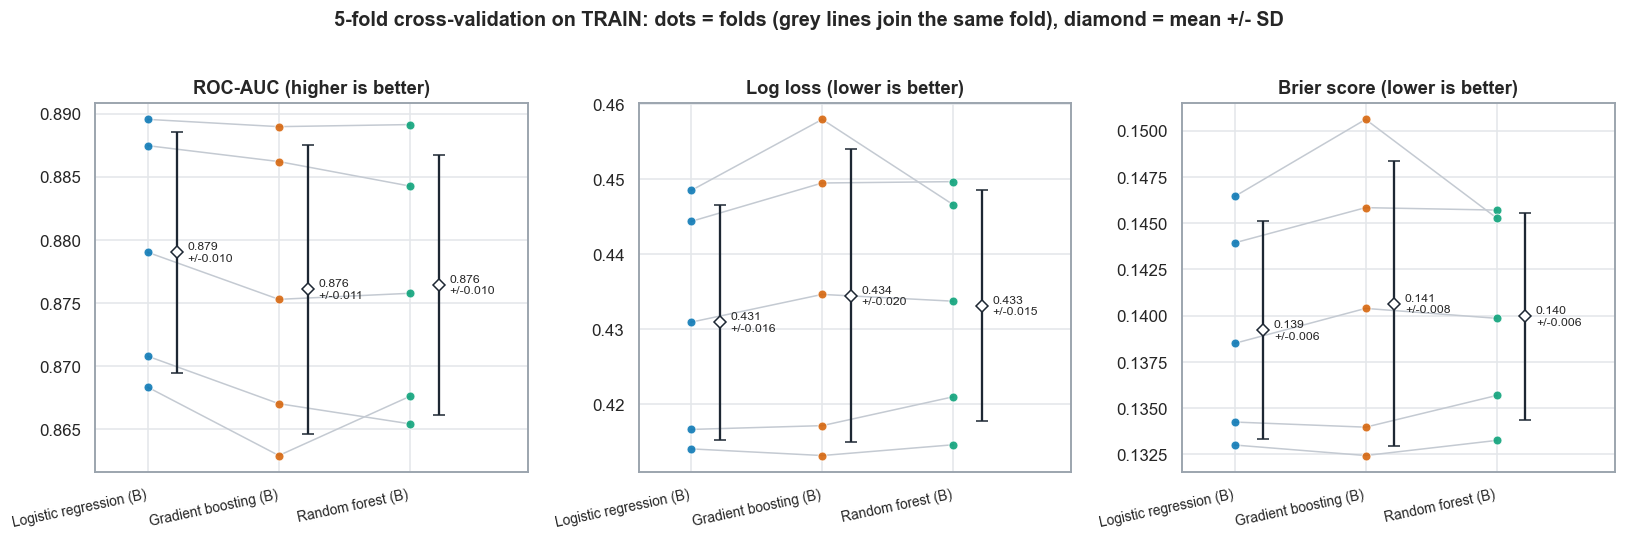

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8)); xs = np.arange(len(MODEL_IDS))
for ax, (met, ttl) in zip(axes, [("roc_auc", "ROC-AUC (higher is better)"), ("log_loss", "Log loss (lower is better)"), ("brier", "Brier score (lower is better)")]):
    piv = folds.pivot(index="fold", columns="model_id", values=met)[MODEL_IDS]
    for k in piv.index: ax.plot(xs, piv.loc[k].values, color="#c4cad2", lw=1, zorder=1)           # same fold connected across models (paired)
    for i, m in enumerate(MODEL_IDS):
        ax.scatter(np.full(len(piv), i), piv[m], color=COL[m], s=34, alpha=0.85, zorder=3, edgecolor="white", linewidth=0.6)
        mu, sd = piv[m].mean(), piv[m].std()
        ax.errorbar(i + 0.22, mu, yerr=sd, fmt="D", color="#1d2733", mfc="white", capsize=4, ms=6, zorder=4)
        ax.text(i + 0.30, mu, f"{mu:.3f}\n+/-{sd:.3f}", fontsize=8, va="center")
    ax.set_xticks(xs); ax.set_xticklabels([LABEL[m] for m in MODEL_IDS], rotation=12, ha="right", fontsize=9); ax.set_xlim(-0.4, 2.9); ax.set_title(ttl)
fig.suptitle("5-fold cross-validation on TRAIN: dots = folds (grey lines join the same fold), diamond = mean +/- SD", y=1.02, fontsize=13, fontweight="semibold")
savefig(fig, "phase5_cv_comparison")

## 4. Part 8: Is the Phase 4 tie stable? (paired fold differences)
All three models are evaluated on the **same five folds**, so differences are paired. For each metric the table gives Logistic minus the other model (negative = logistic regression better for log loss/Brier; positive = better for AUC).
Five folds give very little inferential precision, and fold training sets overlap, so the naive t-interval (SE = s/sqrt(5)) is too narrow. The **Nadeau-Bengio corrected** interval inflates the variance by (1/K + n_test/n_train) / (1/K) = 2.25 for 5-fold CV and is reported as the primary interval; both are shown. Treat them as rough guides, not precise inference.

In [7]:
pd_rows = []
tcrit = stats.t.ppf(0.975, K - 1)
for other in ["GB_B", "RF_B"]:
    for met in ["roc_auc", "log_loss", "brier"]:
        a = folds[folds.model_id == "LR_B"].set_index("fold")[met]; b = folds[folds.model_id == other].set_index("fold")[met]
        d = (a - b).to_numpy(); mu, s = d.mean(), d.std(ddof=1)
        se_naive = s / np.sqrt(K); se_nb = s * np.sqrt(1 / K + (len(outer[0][1]) / len(outer[0][0])))
        pd_rows.append({"comparison": f"LR_B - {other}", "metric": met, "mean_diff": mu, "sd_diff": s, "folds_lr_better": int((d < 0).sum()) if met != "roc_auc" else int((d > 0).sum()),
                        "naive_ci_lo": mu - tcrit * se_naive, "naive_ci_hi": mu + tcrit * se_naive, "nb_ci_lo": mu - tcrit * se_nb, "nb_ci_hi": mu + tcrit * se_nb,
                        "nb_ci_includes_0": (mu - tcrit * se_nb) <= 0 <= (mu + tcrit * se_nb)})
paired = pd.DataFrame(pd_rows); paired.to_csv(MET / "06_cv_paired_differences.csv", index=False)
paired.round(4)

,comparison,metric,mean_diff,sd_diff,folds_lr_better,naive_ci_lo,naive_ci_hi,nb_ci_lo,nb_ci_hi,nb_ci_includes_0
0,LR_B - GB_B,roc_auc,0.0029,0.0020,5,0.0005,0.0054,-0.0008,0.0066,True
1,LR_B - GB_B,log_loss,-0.0036,0.0041,4,-0.0087,0.0015,-0.0112,0.0040,True
2,LR_B - GB_B,brier,-0.0014,0.0019,3,-0.0038,0.0010,-0.0050,0.0022,True
3,LR_B - RF_B,roc_auc,0.0026,0.0020,5,0.0001,0.0051,-0.0012,0.0064,True
4,LR_B - RF_B,log_loss,-0.0022,0.0029,4,-0.0059,0.0014,-0.0077,0.0032,True
5,LR_B - RF_B,brier,-0.0007,0.0012,4,-0.0022,0.0008,-0.0030,0.0015,True


In [8]:
print("Between-model spread of the fold means vs fold-to-fold SD (primary metrics):")
for met in ["roc_auc", "log_loss", "brier"]:
    mu = folds.groupby("model_id")[met].mean()[MODEL_IDS]; sd = folds.groupby("model_id")[met].std()[MODEL_IDS]
    print(f"  {met:9s} range of means = {mu.max() - mu.min():.4f}  | typical fold SD = {sd.mean():.4f}  | ratio = {(mu.max() - mu.min()) / sd.mean():.2f}")

Between-model spread of the fold means vs fold-to-fold SD (primary metrics):
  roc_auc   range of means = 0.0029  | typical fold SD = 0.0104  | ratio = 0.28
  log_loss  range of means = 0.0036  | typical fold SD = 0.0169  | ratio = 0.21
  brier     range of means = 0.0014  | typical fold SD = 0.0064  | ratio = 0.22


## 5. Part 3-4: Calibration of the original probabilities (training OOF predictions)

In [9]:
cal_rows, bin_rows = [], []
for m in MODEL_IDS:
    cm = cal_metrics(OOF[m], y_tr); cal_rows.append({"model_id": m, "model": LABEL[m], "method": "original", "dataset": "train_OOF", "n": len(y_tr), **cm})
    b = quantile_bins(OOF[m], y_tr); b.insert(0, "model_id", m); b.insert(1, "method", "original"); b.insert(2, "dataset", "train_OOF"); bin_rows.append(b)
cal_orig = pd.DataFrame(cal_rows)
cols = ["model", "roc_auc", "log_loss", "brier", "citl", "citl_ci_lo", "citl_ci_hi", "cal_intercept", "cal_slope", "slope_ci_lo", "slope_ci_hi", "ece_quantile", "ece_q_null_mean", "ece_q_null_p95", "ece_uniform", "mean_pred", "obs_rate"]
print("Calibration of ORIGINAL probabilities, training OOF (out-of-sample) predictions:")
display(cal_orig.set_index("model_id")[cols[1:]].round(4).join(cal_orig.set_index("model_id")[["model"]]))

Calibration of ORIGINAL probabilities, training OOF (out-of-sample) predictions:


,roc_auc,log_loss,brier,citl,citl_ci_lo,citl_ci_hi,cal_intercept,cal_slope,slope_ci_lo,slope_ci_hi,ece_quantile,ece_q_null_mean,ece_q_null_p95,ece_uniform,mean_pred,obs_rate,model
model_id,,,,,,,,,,,,,,,,,
LR_B,0.8790,0.4309,0.1392,-0.0004,-0.0640,0.0632,-0.0017,0.9902,0.9461,1.0344,0.0212,0.0107,0.0160,0.0191,0.4156,0.4155,Logistic regression (B)
GB_B,0.8759,0.4345,0.1407,-0.0018,-0.0654,0.0619,-0.0068,0.9766,0.9328,1.0205,0.0159,0.0107,0.0153,0.0187,0.4158,0.4155,Gradient boosting (B)
RF_B,0.8763,0.4331,0.1400,-0.0006,-0.0620,0.0609,0.0163,1.0766,1.0264,1.1269,0.0156,0.0110,0.0159,0.0138,0.4156,0.4155,Random forest (B)


In [10]:
bins_orig = pd.concat(bin_rows, ignore_index=True)
print("Reliability bins (10 equal-count bins of ~%d students each):" % (len(y_tr) // NB))
for m in MODEL_IDS:
    print(f"--- {LABEL[m]} ---"); display(bins_orig[bins_orig.model_id == m].drop(columns=["model_id", "method", "dataset"]).set_index("bin").round(3))

Reliability bins (10 equal-count bins of ~693 students each):
--- Logistic regression (B) ---


,n,p_min,p_max,mean_pred,obs_rate,calibration_gap,ci_lo,ci_hi
bin,,,,,,,,
1,694,0.005,0.035,0.022,0.014,0.007,0.008,0.026
2,694,0.035,0.074,0.052,0.055,-0.003,0.040,0.074
3,694,0.074,0.125,0.098,0.110,-0.012,0.088,0.135
4,694,0.125,0.211,0.163,0.177,-0.014,0.151,0.207
5,694,0.211,0.349,0.276,0.313,-0.036,0.279,0.348
6,694,0.349,0.522,0.433,0.422,0.011,0.386,0.459
7,694,0.522,0.682,0.605,0.550,0.055,0.513,0.587
8,694,0.682,0.809,0.749,0.722,0.027,0.687,0.754
9,693,0.810,0.884,0.850,0.844,0.006,0.815,0.869


--- Gradient boosting (B) ---


,n,p_min,p_max,mean_pred,obs_rate,calibration_gap,ci_lo,ci_hi
bin,,,,,,,,
1,694,0.008,0.043,0.028,0.016,0.013,0.009,0.028
2,694,0.043,0.081,0.060,0.059,0.001,0.044,0.079
3,694,0.081,0.132,0.104,0.120,-0.016,0.098,0.146
4,694,0.132,0.210,0.167,0.173,-0.006,0.147,0.203
5,694,0.210,0.337,0.270,0.314,-0.044,0.281,0.350
6,694,0.337,0.500,0.417,0.418,-0.001,0.382,0.455
7,694,0.502,0.660,0.583,0.550,0.032,0.513,0.587
8,694,0.660,0.804,0.737,0.728,0.009,0.693,0.759
9,693,0.804,0.904,0.858,0.833,0.026,0.803,0.859


--- Random forest (B) ---


,n,p_min,p_max,mean_pred,obs_rate,calibration_gap,ci_lo,ci_hi
bin,,,,,,,,
1,694,0.006,0.046,0.027,0.026,0.001,0.016,0.041
2,694,0.046,0.089,0.067,0.042,0.026,0.029,0.059
3,694,0.089,0.156,0.120,0.122,-0.002,0.100,0.149
4,694,0.156,0.249,0.201,0.183,0.018,0.156,0.213
5,694,0.249,0.361,0.305,0.284,0.021,0.252,0.319
6,694,0.361,0.491,0.426,0.448,-0.022,0.412,0.485
7,694,0.491,0.620,0.555,0.542,0.013,0.505,0.579
8,694,0.620,0.763,0.693,0.710,-0.018,0.676,0.743
9,693,0.763,0.887,0.829,0.844,-0.015,0.815,0.869


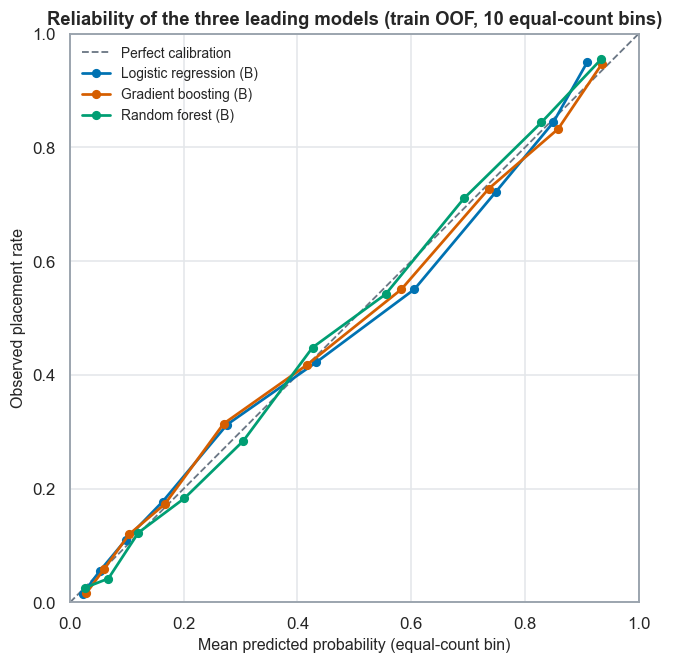

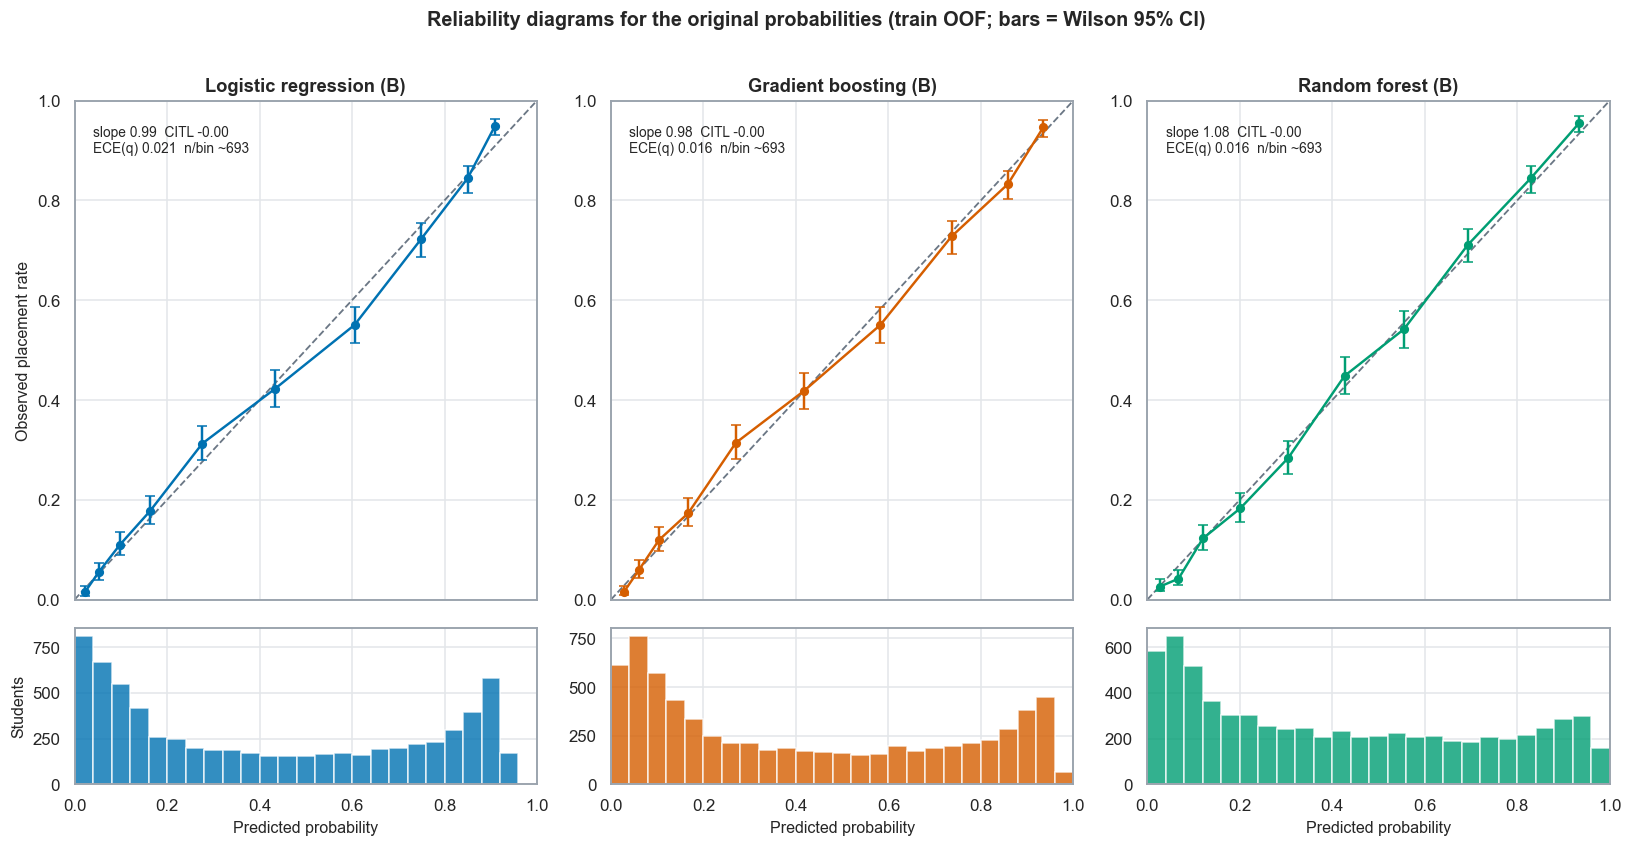

In [11]:
# Reliability: overlay of the three original models
fig, ax = plt.subplots(figsize=(6.6, 6.2))
ax.plot([0, 1], [0, 1], color=NEUTRAL, ls="--", lw=1.2, label="Perfect calibration")
for m in MODEL_IDS:
    b = bins_orig[bins_orig.model_id == m]; ax.plot(b.mean_pred, b.obs_rate, "o-", color=COL[m], lw=1.8, ms=5, label=LABEL[m])
ax.set_xlabel("Mean predicted probability (equal-count bin)"); ax.set_ylabel("Observed placement rate"); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
ax.set_title("Reliability of the three leading models (train OOF, 10 equal-count bins)"); ax.legend(frameon=False, loc="upper left", fontsize=9)
savefig(fig, "phase5_reliability_curves")

# Reliability per model with Wilson intervals and prediction histograms
fig, axes = plt.subplots(2, 3, figsize=(15, 7.6), gridspec_kw={"height_ratios": [3.2, 1]}, sharex="col")
for j, m in enumerate(MODEL_IDS):
    b = bins_orig[bins_orig.model_id == m]; ax = axes[0, j]
    ax.plot([0, 1], [0, 1], color=NEUTRAL, ls="--", lw=1.2)
    ax.errorbar(b.mean_pred, b.obs_rate, yerr=[b.obs_rate - b.ci_lo, b.ci_hi - b.obs_rate], fmt="o-", color=COL[m], ecolor=COL[m], capsize=3, lw=1.6, ms=5)
    cmx = cal_orig.set_index("model_id").loc[m]
    ax.text(0.04, 0.95, f"slope {cmx.cal_slope:.2f}  CITL {cmx.citl:+.2f}\nECE(q) {cmx.ece_quantile:.3f}  n/bin ~{int(b.n.mean())}", transform=ax.transAxes, va="top", fontsize=9)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_title(LABEL[m]); ax.set_ylabel("Observed placement rate" if j == 0 else "")
    axes[1, j].hist(OOF[m], bins=np.linspace(0, 1, 26), color=COL[m], alpha=0.8); axes[1, j].set_xlabel("Predicted probability"); axes[1, j].set_ylabel("Students" if j == 0 else "")
fig.suptitle("Reliability diagrams for the original probabilities (train OOF; bars = Wilson 95% CI)", y=1.01, fontsize=13, fontweight="semibold")
savefig(fig, "phase5_reliability_original")

## 6. Part 5: Recalibration - nested, leakage-safe comparison of Original vs Sigmoid vs Isotonic (TRAIN only)
**Procedure (for every outer CV fold k and each model):**
1. Fit the pipeline on the outer-training portion and predict the held-out fold: these are the *original* probabilities (identical to the OOF predictions above; asserted).
2. *Inner* 5-fold CV **within the outer-training portion only**: obtain out-of-sample probabilities for every outer-training student.
3. Fit the calibration map on those inner out-of-sample probabilities: **sigmoid (Platt)** = unpenalised logistic regression of the outcome on `logit(p)` (two parameters: slope and intercept); **isotonic** = monotone non-decreasing step function (`IsotonicRegression`, out-of-bounds clipped; outputs clipped to [0.001, 0.999] to avoid infinite log loss).
4. Apply the map to the held-out fold's original probabilities.

The held-out fold is never used to fit the base model *or* the calibration map, so every calibrated training probability is genuinely out-of-sample; calibration metrics are computed on these pooled nested predictions and per fold. No validation or test data are used. Isotonic is flexible (many parameters) and can over-fit with small samples; sigmoid can only fix a monotone logistic-shaped miscalibration.

In [12]:
def fit_sigmoid(p, y):
    lr = LogisticRegression(C=np.inf, solver="lbfgs", max_iter=2000).fit(logit(p).reshape(-1, 1), y)
    f = lambda q: lr.predict_proba(logit(q).reshape(-1, 1))[:, 1]; f.params = (float(lr.intercept_[0]), float(lr.coef_[0, 0])); return f

def fit_isotonic(p, y):
    iso = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds="clip", increasing=True).fit(p, y)
    return lambda q: np.clip(iso.predict(q), 1e-3, 1 - 1e-3)

CAL = {m: {"original": OOF[m].copy(), "sigmoid": np.full(len(y_tr), np.nan), "isotonic": np.full(len(y_tr), np.nan)} for m in MODEL_IDS}
rfold, sig_params = [], []
t0 = time.time()
for k, (tr, te) in enumerate(outer, 1):
    inner = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED + k)
    for m in MODEL_IDS:
        p_in = np.full(len(tr), np.nan)
        for itr, ite in inner.split(X_tr.iloc[tr], y_tr[tr]):
            pipe = clone(BASE[m]).fit(X_tr.iloc[tr[itr]], y_tr[tr[itr]]); p_in[ite] = pipe.predict_proba(X_tr.iloc[tr[ite]])[:, 1]
        assert not np.isnan(p_in).any()
        sg, io = fit_sigmoid(p_in, y_tr[tr]), fit_isotonic(p_in, y_tr[tr])
        CAL[m]["sigmoid"][te] = sg(OOF[m][te]); CAL[m]["isotonic"][te] = io(OOF[m][te])
        sig_params.append({"model_id": m, "fold": k, "sigmoid_intercept": sg.params[0], "sigmoid_slope": sg.params[1]})
        for meth in ["original", "sigmoid", "isotonic"]:
            mm = clf_metrics(CAL[m][meth][te], y_tr[te]); rfold.append({"model_id": m, "method": meth, "fold": k, **mm})
print(f"Nested calibration done in {time.time() - t0:.0f}s")
assert all(not np.isnan(CAL[m][x]).any() for m in MODEL_IDS for x in ("sigmoid", "isotonic"))
recal_fold = pd.DataFrame(rfold); recal_fold.to_csv(MET / "06_recalibration_fold_results.csv", index=False)
sig_df = pd.DataFrame(sig_params); sig_df.to_csv(MET / "06_sigmoid_parameters_by_fold.csv", index=False)
print("Sigmoid map per outer fold, logit(p_cal) = intercept + slope * logit(p):"); display(sig_df.pivot(index="fold", columns="model_id", values="sigmoid_slope").round(3).add_prefix("slope_").join(sig_df.pivot(index="fold", columns="model_id", values="sigmoid_intercept").round(3).add_prefix("intercept_")))

Nested calibration done in 158s
Sigmoid map per outer fold, logit(p_cal) = intercept + slope * logit(p):


model_id,slope_GB_B,slope_LR_B,slope_RF_B,intercept_GB_B,intercept_LR_B,intercept_RF_B
fold,,,,,,
1,0.970,0.991,1.073,-0.007,0.001,0.013
2,0.971,0.991,1.079,-0.002,-0.001,0.020
3,0.976,0.991,1.078,-0.009,0.000,0.013
4,0.966,0.991,1.069,-0.008,-0.002,0.011
5,0.973,0.988,1.085,-0.006,0.000,0.017


In [13]:
rows, bins_all = [], [bins_orig]
for m in MODEL_IDS:
    for meth in ["original", "sigmoid", "isotonic"]:
        p = CAL[m][meth]; cm = cal_metrics(p, y_tr)
        rows.append({"model_id": m, "model": LABEL[m], "method": meth, "dataset": "train_nested_CV", "n": len(y_tr), **cm,
                     "n_distinct_probabilities": int(len(np.unique(np.round(p, 8)))), "share_p_at_clip_bounds_%": float(((p <= 1e-3 + 1e-12) | (p >= 1 - 1e-3 - 1e-12)).mean() * 100)})
        if meth != "original":
            b = quantile_bins(p, y_tr); b.insert(0, "model_id", m); b.insert(1, "method", meth); b.insert(2, "dataset", "train_nested_CV"); bins_all.append(b)
# paired bootstrap of the change vs original (same resamples for all models/methods)
rng = np.random.default_rng(SEED); IDX = rng.integers(0, len(y_tr), (B_BOOT, len(y_tr)))
def ll_vec(p, y): q = np.clip(p, 1e-15, 1 - 1e-15); return -(y * np.log(q) + (1 - y) * np.log(1 - q))
rc = pd.DataFrame(rows)
for i, r in rc.iterrows():
    if r.method == "original": continue
    for met, vec in [("log_loss", lambda p: ll_vec(p, y_tr)), ("brier", lambda p: (p - y_tr) ** 2)]:
        d = (vec(CAL[r.model_id][r.method]) - vec(CAL[r.model_id]["original"]))[IDX].mean(axis=1)
        rc.loc[i, f"d_{met}"] = d.mean(); rc.loc[i, f"d_{met}_ci_lo"], rc.loc[i, f"d_{met}_ci_hi"] = np.percentile(d, [2.5, 97.5])
base_auc = rc[rc.method == "original"].set_index("model_id").roc_auc
rc["d_roc_auc"] = rc.apply(lambda r: np.nan if r.method == "original" else r.roc_auc - base_auc[r.model_id], axis=1)
rc.to_csv(MET / "06_recalibration_comparison.csv", index=False)
pd.concat(bins_all, ignore_index=True).to_csv(MET / "06_calibration_bins.csv", index=False)
show = ["model_id", "method", "roc_auc", "d_roc_auc", "log_loss", "d_log_loss", "d_log_loss_ci_lo", "d_log_loss_ci_hi", "brier", "d_brier", "d_brier_ci_lo", "d_brier_ci_hi", "citl", "cal_intercept", "cal_slope", "ece_quantile", "ece_q_null_mean", "ece_q_null_p95", "ece_uniform"]
print("Original vs sigmoid vs isotonic, TRAIN, nested leakage-safe (d_* = change vs original; negative log loss/Brier change = improvement):")
rc[show].set_index(["model_id", "method"]).round(4)

Original vs sigmoid vs isotonic, TRAIN, nested leakage-safe (d_* = change vs original; negative log loss/Brier change = improvement):


roc_auc  d_roc_auc  log_loss  d_log_loss  d_log_loss_ci_lo  d_log_loss_ci_hi   brier  d_brier  d_brier_ci_lo  d_brier_ci_hi    citl  cal_intercept  cal_slope  ece_quantile  \
model_id method                                                                                                                                                                                  
LR_B     original   0.8790        NaN    0.4309         NaN               NaN               NaN  0.1392      NaN            NaN            NaN -0.0004        -0.0017     0.9902        0.0212   
         sigmoid    0.8790     0.0000    0.4309     -0.0000           -0.0001            0.0001  0.1392  -0.0000        -0.0001        -0.0000 -0.0015        -0.0015     0.9999        0.0203   
         isotonic   0.8773    -0.0016    0.4302     -0.0008           -0.0034            0.0018  0.1391  -0.0001        -0.0008         0.0005 -0.0011        -0.0076     0.9684        0.0088   
GB_B     original   0.8759        NaN    0.4345         NaN               NaN               NaN  0.1407      NaN            NaN            NaN -0.0018        -0.0068     0.9766        0.0159   
         sigmoid    0.8758    -0.0000    0.4344     -0.0000           -0.0004            0.0003  0.1406  -0.0001        -0.0002        -0.0000 -0.0016        -0.0004     1.0055        0.0134   
         isotonic   0.8744    -0.0015    0.4359      0.0015           -0.0008            0.0037  0.1407   0.0001        -0.0006         0.0007 -0.0040        -0.0100     0.9724        0.0078   
RF_B     original   0.8763        NaN    0.4331         NaN               NaN               NaN  0.1400      NaN            NaN            NaN -0.0006         0.0163     1.0766        0.0156   
         sigmoid    0.8763    -0.0000    0.4325     -0.0006           -0.0015            0.0002  0.1398  -0.0001        -0.0003         0.0001  0.0015         0.0015     0.9998        0.0103   
         isotonic   0.8746    -0.0017    0.4360      0.0029            0.0006            0.0052  0.1406   0.0006         0.0001         0.0011 -0.0004        -0.0087     0.9634        0.0086   

                   ece_q_null_mean  ece_q_null_p95  ece_uniform  
model_id method                                                  
LR_B     original           0.0107          0.0160       0.0191  
         sigmoid            0.0108          0.0158       0.0187  
         isotonic           0.0105          0.0153       0.0081  
GB_B     original           0.0107          0.0153       0.0187  
         sigmoid            0.0108          0.0154       0.0167  
         isotonic           0.0106          0.0153       0.0081  
RF_B     original           0.0110          0.0159       0.0138  
         sigmoid            0.0106          0.0151       0.0075  
         isotonic           0.0105          0.0152       0.0073

In [14]:
# Calibration-metrics file requested for the original probabilities (+ recalibrated versions, clearly labelled)
cm_out = rc[["model_id", "model", "method", "dataset", "n", "roc_auc", "log_loss", "brier", "citl", "citl_ci_lo", "citl_ci_hi", "cal_intercept", "cal_slope", "slope_ci_lo", "slope_ci_hi",
             "ece_quantile", "ece_q_null_mean", "ece_q_null_p95", "ece_uniform", "mean_pred", "obs_rate"]]
cm_out.to_csv(MET / "06_calibration_metrics.csv", index=False)
print("AUC check - does recalibration change ranking?  (isotonic can create ties; sigmoid is monotone and should leave AUC unchanged)")
display(rc[rc.method != "original"].pivot(index="model_id", columns="method", values="d_roc_auc").round(5))
print("Isotonic: distinct output values and share of predictions at the clip bounds:")
display(rc[rc.method == "isotonic"].set_index("model_id")[["n_distinct_probabilities", "share_p_at_clip_bounds_%"]].round(2))
for m in MODEL_IDS:        # consistency with Part 2: the 'original' arm equals the OOF predictions
    assert np.allclose(CAL[m]["original"], OOF[m])

AUC check - does recalibration change ranking?  (isotonic can create ties; sigmoid is monotone and should leave AUC unchanged)


method,isotonic,sigmoid
model_id,,
GB_B,-0.00148,-0.00003
LR_B,-0.00164,0.00000
RF_B,-0.00171,-0.00002


Isotonic: distinct output values and share of predictions at the clip bounds:


,n_distinct_probabilities,share_p_at_clip_bounds_%
model_id,,
LR_B,224,2.51
GB_B,216,0.78
RF_B,239,2.22


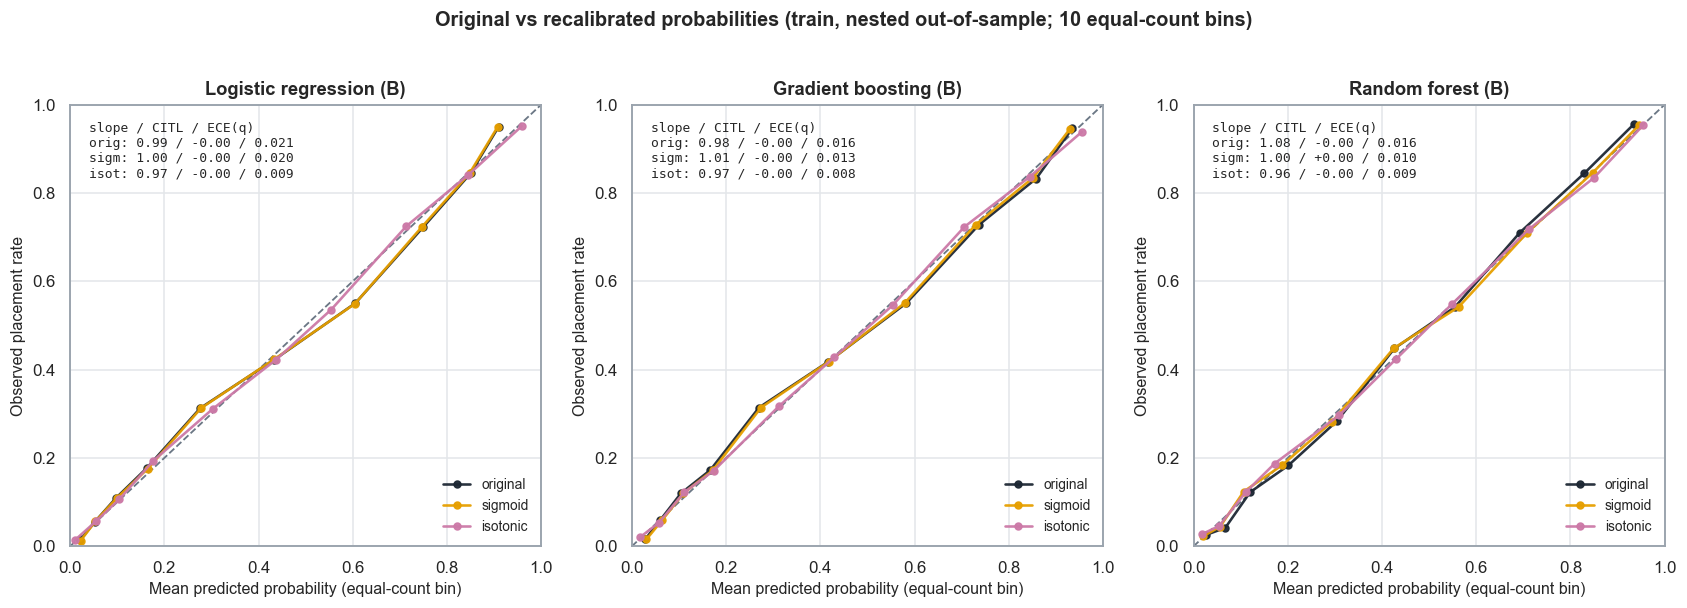

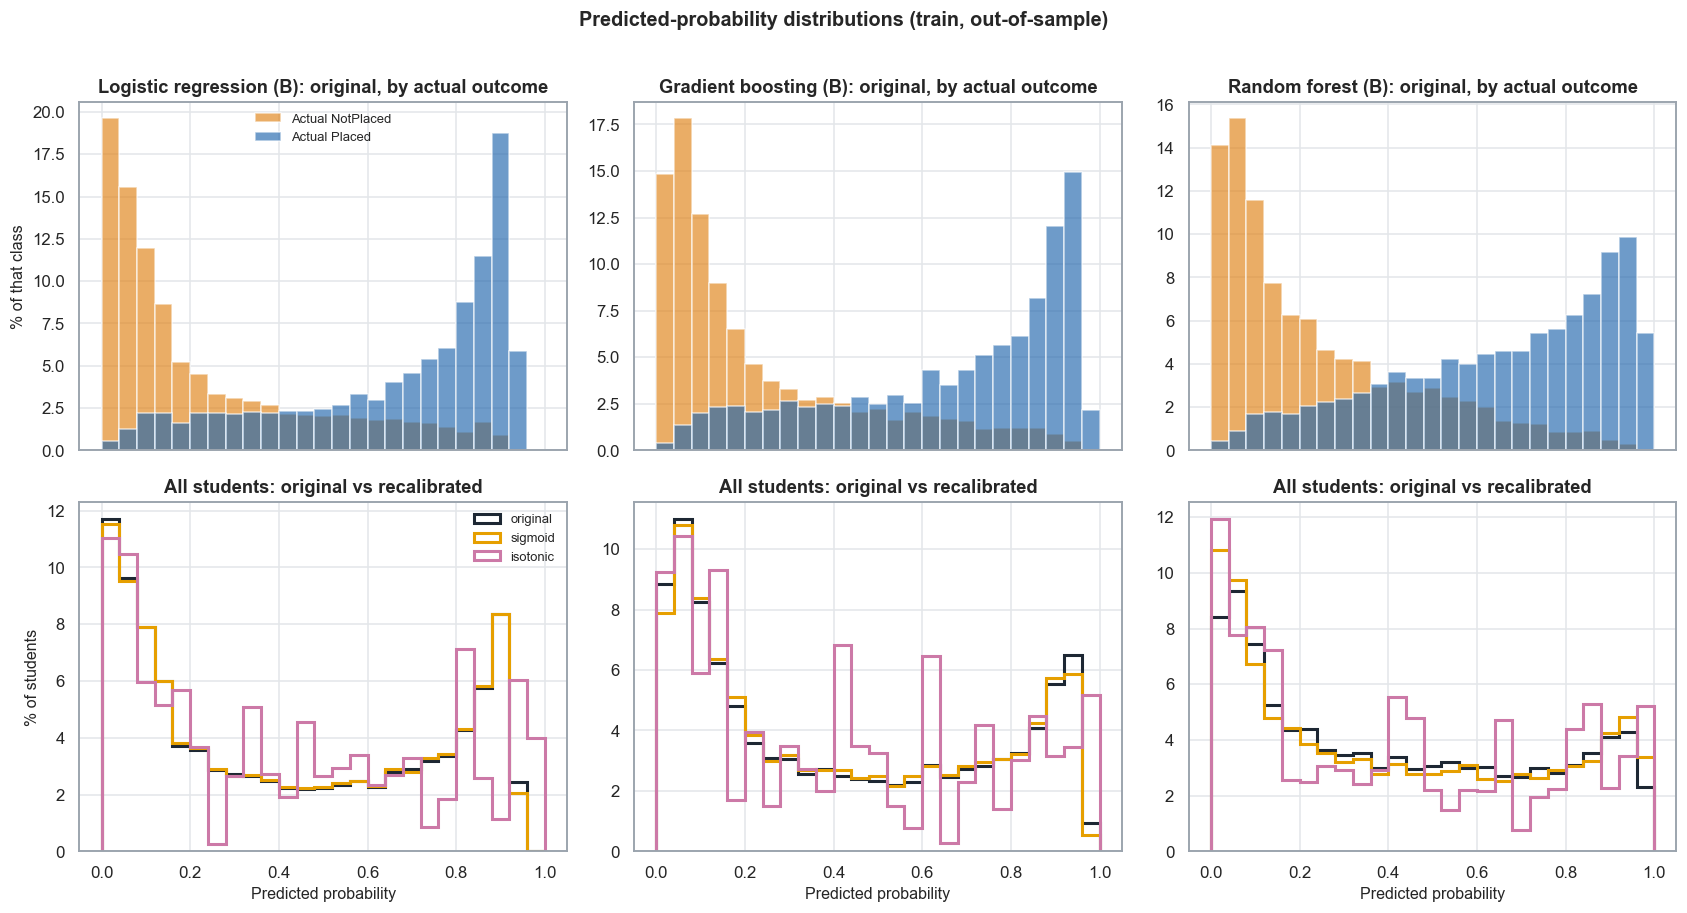

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.4))
for ax, m in zip(axes, MODEL_IDS):
    ax.plot([0, 1], [0, 1], color=NEUTRAL, ls="--", lw=1.2)
    for meth in ["original", "sigmoid", "isotonic"]:
        b = quantile_bins(CAL[m][meth], y_tr)
        ax.plot(b.mean_pred, b.obs_rate, "o-", color=METH_C[meth], lw=1.7, ms=4.5, label=meth, alpha=0.95)
    r_ = rc.set_index(["model_id", "method"])
    ax.text(0.04, 0.96, "slope / CITL / ECE(q)\n" + "\n".join(f"{x[:4]}: {r_.loc[(m, x), 'cal_slope']:.2f} / {r_.loc[(m, x), 'citl']:+.2f} / {r_.loc[(m, x), 'ece_quantile']:.3f}" for x in ["original", "sigmoid", "isotonic"]),
            transform=ax.transAxes, va="top", fontsize=8.5, family="monospace")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel("Mean predicted probability (equal-count bin)"); ax.set_ylabel("Observed placement rate"); ax.set_title(LABEL[m]); ax.legend(frameon=False, loc="lower right", fontsize=9)
fig.suptitle("Original vs recalibrated probabilities (train, nested out-of-sample; 10 equal-count bins)", y=1.02, fontsize=13, fontweight="semibold")
savefig(fig, "phase5_reliability_recalibrated")

fig, axes = plt.subplots(2, 3, figsize=(15.5, 8.2), sharex=True)
BINS = np.linspace(0, 1, 26)
for j, m in enumerate(MODEL_IDS):
    p = OOF[m]
    axes[0, j].hist(p[y_tr == 0], bins=BINS, color=NOT_C, alpha=0.65, weights=np.full((y_tr == 0).sum(), 100 / (y_tr == 0).sum()), label="Actual NotPlaced")
    axes[0, j].hist(p[y_tr == 1], bins=BINS, color=PLACED_C, alpha=0.65, weights=np.full((y_tr == 1).sum(), 100 / (y_tr == 1).sum()), label="Actual Placed")
    axes[0, j].set_title(f"{LABEL[m]}: original, by actual outcome"); axes[0, j].set_ylabel("% of that class" if j == 0 else "")
    for meth in ["original", "sigmoid", "isotonic"]:
        axes[1, j].hist(CAL[m][meth], bins=BINS, histtype="step", lw=2, color=METH_C[meth], label=meth, weights=np.full(len(y_tr), 100 / len(y_tr)))
    axes[1, j].set_xlabel("Predicted probability"); axes[1, j].set_title("All students: original vs recalibrated"); axes[1, j].set_ylabel("% of students" if j == 0 else "")
axes[0, 0].legend(frameon=False, fontsize=8.5); axes[1, 0].legend(frameon=False, fontsize=8.5)
fig.suptitle("Predicted-probability distributions (train, out-of-sample)", y=1.01, fontsize=13, fontweight="semibold")
savefig(fig, "phase5_probability_distributions")

**Distribution summary (original probabilities, train OOF).** A confident (extreme) probability is not evidence of a good prediction: it is only informative if the reliability diagram shows the observed rate matches it. For each model: quantiles of the predicted probability, the share of students in the low (< 0.2), middle (0.2-0.8) and high (> 0.8) bands, and - for the two extreme bands - the *observed* placement rate in that band, which is the check that the confidence is justified.

In [16]:
drows = []
for m in MODEL_IDS:
    p = OOF[m]; low, mid, high = p < 0.2, (p >= 0.2) & (p <= 0.8), p > 0.8
    drows.append({"model_id": m, "model": LABEL[m], "min": p.min(), **{f"q{int(q * 100):02d}": np.quantile(p, q) for q in (0.05, 0.25, 0.50, 0.75, 0.95)}, "max": p.max(),
                  "share_below_0.2": low.mean(), "share_0.2_to_0.8": mid.mean(), "share_above_0.8": high.mean(),
                  "observed_rate_below_0.2": y_tr[low].mean(), "observed_rate_0.2_to_0.8": y_tr[mid].mean(), "observed_rate_above_0.8": y_tr[high].mean(),
                  "mean_pred_below_0.2": p[low].mean(), "mean_pred_above_0.8": p[high].mean()})
dist = pd.DataFrame(drows); dist.to_csv(MET / "06_probability_distribution_summary.csv", index=False)
dist.set_index("model_id").drop(columns="model").round(3).T

model_id,LR_B,GB_B,RF_B
min,0.005,0.008,0.006
q05,0.022,0.029,0.027
q25,0.097,0.103,0.119
q50,0.349,0.337,0.361
q75,0.748,0.738,0.692
q95,0.909,0.935,0.935
max,0.949,0.976,0.979
share_below_0.2,0.389,0.391,0.348
share_0.2_to_0.8,0.402,0.406,0.478
share_above_0.8,0.208,0.203,0.173


## 7. Part 6: Calibration-method decision (evidence, not sophistication)
**Pre-declared materiality rule.** A recalibration method is judged to *materially* improve probability quality for a model only if **both** hold in the nested train analysis: (i) the paired-bootstrap 95% CI for the change in log loss lies entirely below 0 **and** the point improvement is at least 0.005 (about 1% of the 0.44 log loss), and (ii) the Brier change is also negative with a CI below 0. The bootstrap resamples students from pooled OOF predictions and ignores fold dependence, so it slightly understates uncertainty; the per-fold consistency table below is a second check. Smaller changes are called *negligible*, whatever their p-value or CI. Calibration slope/intercept, the reliability curves, the sample size per parameter, and fold-to-fold stability are read alongside.

In [17]:
sel = rc[rc.method != "original"].copy()
sel["material"] = (sel.d_log_loss <= -0.005) & (sel.d_log_loss_ci_hi < 0) & (sel.d_brier_ci_hi < 0)
rf_ = recal_fold.pivot_table(index=["model_id", "fold"], columns="method", values="log_loss")
for meth in ["sigmoid", "isotonic"]:
    d = (rf_[meth] - rf_["original"]).groupby("model_id")
    sel[f"folds_improved_{meth}"] = sel.model_id.map(d.apply(lambda s: int((s < 0).sum()))).where(sel.method == meth)
    sel[f"mean_fold_dLL_{meth}"] = sel.model_id.map(d.mean()).where(sel.method == meth)
decision = sel[["model_id", "method", "d_log_loss", "d_log_loss_ci_lo", "d_log_loss_ci_hi", "d_brier", "d_brier_ci_lo", "d_brier_ci_hi", "cal_slope", "citl", "ece_quantile", "material", "folds_improved_sigmoid", "folds_improved_isotonic"]]
decision.round(4).set_index(["model_id", "method"])

d_log_loss  d_log_loss_ci_lo  d_log_loss_ci_hi  d_brier  d_brier_ci_lo  d_brier_ci_hi  cal_slope    citl  ece_quantile  material  folds_improved_sigmoid  folds_improved_isotonic
model_id method                                                                                                                                                                                     
LR_B     sigmoid      -0.0000           -0.0001            0.0001  -0.0000        -0.0001        -0.0000     0.9999 -0.0015        0.0203     False                     2.0                      NaN
         isotonic     -0.0008           -0.0034            0.0018  -0.0001        -0.0008         0.0005     0.9684 -0.0011        0.0088     False                     NaN                      3.0
GB_B     sigmoid      -0.0000           -0.0004            0.0003  -0.0001        -0.0002        -0.0000     1.0055 -0.0016        0.0134     False                     2.0                      NaN
         isotonic      0.0015           -0.0008            0.0037   0.0001        -0.0006         0.0007     0.9724 -0.0040        0.0078     False                     NaN                      1.0
RF_B     sigmoid      -0.0006           -0.0015            0.0002  -0.0001        -0.0003         0.0001     0.9998  0.0015        0.0103     False                     3.0                      NaN
         isotonic      0.0029            0.0006            0.0052   0.0006         0.0001         0.0011     0.9634 -0.0004        0.0086     False                     NaN                      0.0

In [18]:
orig = rc[rc.method == "original"].set_index("model_id")
print("Original slope / CITL / ECE(q):", {m: (round(orig.loc[m, 'cal_slope'], 3), round(orig.loc[m, 'citl'], 3), round(orig.loc[m, 'ece_quantile'], 4)) for m in MODEL_IDS})
for m in MODEL_IDS:
    s = sel[sel.model_id == m]; print(f"{m}: material recalibration -> {dict(zip(s.method, s.material))}")
decision.to_csv(MET / "06_calibration_method_decision.csv", index=False)

Original slope / CITL / ECE(q): {'LR_B': (np.float64(0.99), np.float64(-0.0), np.float64(0.0212)), 'GB_B': (np.float64(0.977), np.float64(-0.002), np.float64(0.0159)), 'RF_B': (np.float64(1.077), np.float64(-0.001), np.float64(0.0156))}
LR_B: material recalibration -> {'sigmoid': False, 'isotonic': False}
GB_B: material recalibration -> {'sigmoid': False, 'isotonic': False}
RF_B: material recalibration -> {'sigmoid': False, 'isotonic': False}


## 8. Part 7: Validation-set confirmation (calibrators fitted on TRAIN only)
The base models are fitted on the **full training set** (as in Phase 4; predictions are asserted to match the saved Phase 4 validation predictions). Calibration maps are fitted **only on the training OOF probabilities** from section 3 (each from a model that did not see that student), then applied to the validation predictions. The validation set is used purely to evaluate. This is a *confirmation*, kept separate from the training-CV estimates, and the validation set remains the model-development set (no threshold tuning, no new search).
Note the small mismatch inherent in this standard recipe: OOF probabilities come from models trained on 80% of the training data, while the final models use 100%.

In [19]:
p4 = pd.read_csv(MET / "05_validation_predictions.csv")            # Phase 4 validation predictions (validation data only)
assert (p4.y_true.to_numpy() == y_va).all()
VAL = {}; vrows, vbins = [], []
for m in MODEL_IDS:
    full = clone(BASE[m]).fit(X_tr, y_tr); p_raw = full.predict_proba(X_va)[:, 1]
    assert np.allclose(p_raw, p4[m].to_numpy(), atol=1e-8), f"{m}: refit does not reproduce Phase 4 validation predictions"
    sg, io = fit_sigmoid(OOF[m], y_tr), fit_isotonic(OOF[m], y_tr)               # calibrators from TRAIN OOF only
    VAL[m] = {"original": p_raw, "sigmoid": sg(p_raw), "isotonic": io(p_raw)}
    for meth, p in VAL[m].items():
        vrows.append({"model_id": m, "model": LABEL[m], "method": meth, "dataset": "validation_confirmation", "n": len(y_va), **cal_metrics(p, y_va)})
        b = quantile_bins(p, y_va); b.insert(0, "model_id", m); b.insert(1, "method", meth); b.insert(2, "dataset", "validation"); vbins.append(b)
print("Refit models reproduce the Phase 4 validation probabilities exactly.")
rng2 = np.random.default_rng(SEED + 7); IDXV = rng2.integers(0, len(y_va), (B_BOOT, len(y_va)))
vc = pd.DataFrame(vrows)
for i, r in vc.iterrows():
    if r.method == "original": continue
    for met, vec in [("log_loss", lambda p: ll_vec(p, y_va)), ("brier", lambda p: (p - y_va) ** 2)]:
        d = (vec(VAL[r.model_id][r.method]) - vec(VAL[r.model_id]["original"]))[IDXV].mean(axis=1)
        vc.loc[i, f"d_{met}"] = d.mean(); vc.loc[i, f"d_{met}_ci_lo"], vc.loc[i, f"d_{met}_ci_hi"] = np.percentile(d, [2.5, 97.5])
vc.to_csv(MET / "06_validation_confirmation.csv", index=False)
pd.concat(vbins, ignore_index=True).to_csv(MET / "06_validation_calibration_bins.csv", index=False)
pd.DataFrame({"y_true": y_va, **{f"{m}_{meth}": VAL[m][meth] for m in MODEL_IDS for meth in VAL[m]}}).to_csv(MET / "06_validation_confirmation_predictions.csv", index=False)
print("VALIDATION confirmation (train-fitted calibrators):")
vc[["model_id", "method", "roc_auc", "log_loss", "d_log_loss", "d_log_loss_ci_lo", "d_log_loss_ci_hi", "brier", "d_brier", "citl", "cal_intercept", "cal_slope", "slope_ci_lo", "slope_ci_hi", "ece_quantile", "ece_q_null_mean", "ece_q_null_p95", "ece_uniform"]].set_index(["model_id", "method"]).round(4)

Refit models reproduce the Phase 4 validation probabilities exactly.
VALIDATION confirmation (train-fitted calibrators):


roc_auc  log_loss  d_log_loss  d_log_loss_ci_lo  d_log_loss_ci_hi   brier  d_brier    citl  cal_intercept  cal_slope  slope_ci_lo  slope_ci_hi  ece_quantile  ece_q_null_mean  \
model_id method                                                                                                                                                                                    
LR_B     original   0.8717    0.4408         NaN               NaN               NaN  0.1409      NaN  0.0434         0.0393     0.9793       0.8840       1.0746        0.0241           0.0234   
         sigmoid    0.8717    0.4408     -0.0000           -0.0003            0.0002  0.1409   0.0000  0.0432         0.0410     0.9890       0.8928       1.0852        0.0242           0.0235   
         isotonic   0.8711    0.4420      0.0012           -0.0039            0.0072  0.1416   0.0007  0.0431         0.0324     0.9608       0.8597       1.0618        0.0236           0.0231   
GB_B     original   0.8706    0.4413         NaN               NaN               NaN  0.1417      NaN  0.0358         0.0293     0.9764       0.8808       1.0721        0.0181           0.0231   
         sigmoid    0.8706    0.4412     -0.0001           -0.0007            0.0005  0.1417  -0.0000  0.0362         0.0361     0.9999       0.9020       1.0978        0.0190           0.0234   
         isotonic   0.8699    0.4428      0.0015           -0.0025            0.0059  0.1423   0.0006  0.0316         0.0237     0.9708       0.8696       1.0720        0.0263           0.0232   
RF_B     original   0.8693    0.4432         NaN               NaN               NaN  0.1431      NaN  0.0358         0.0559     1.0714       0.9622       1.1806        0.0329           0.0241   
         sigmoid    0.8693    0.4426     -0.0005           -0.0024            0.0013  0.1428  -0.0003  0.0409         0.0395     0.9950       0.8936       1.0965        0.0297           0.0234   
         isotonic   0.8682    0.4462      0.0031           -0.0009            0.0072  0.1439   0.0009  0.0306         0.0194     0.9618       0.8619       1.0618        0.0276           0.0231   

                   ece_q_null_p95  ece_uniform  
model_id method                                 
LR_B     original          0.0337       0.0200  
         sigmoid           0.0338       0.0185  
         isotonic          0.0332       0.0278  
GB_B     original          0.0336       0.0197  
         sigmoid           0.0338       0.0195  
         isotonic          0.0333       0.0227  
RF_B     original          0.0342       0.0256  
         sigmoid           0.0332       0.0236  
         isotonic          0.0326       0.0248

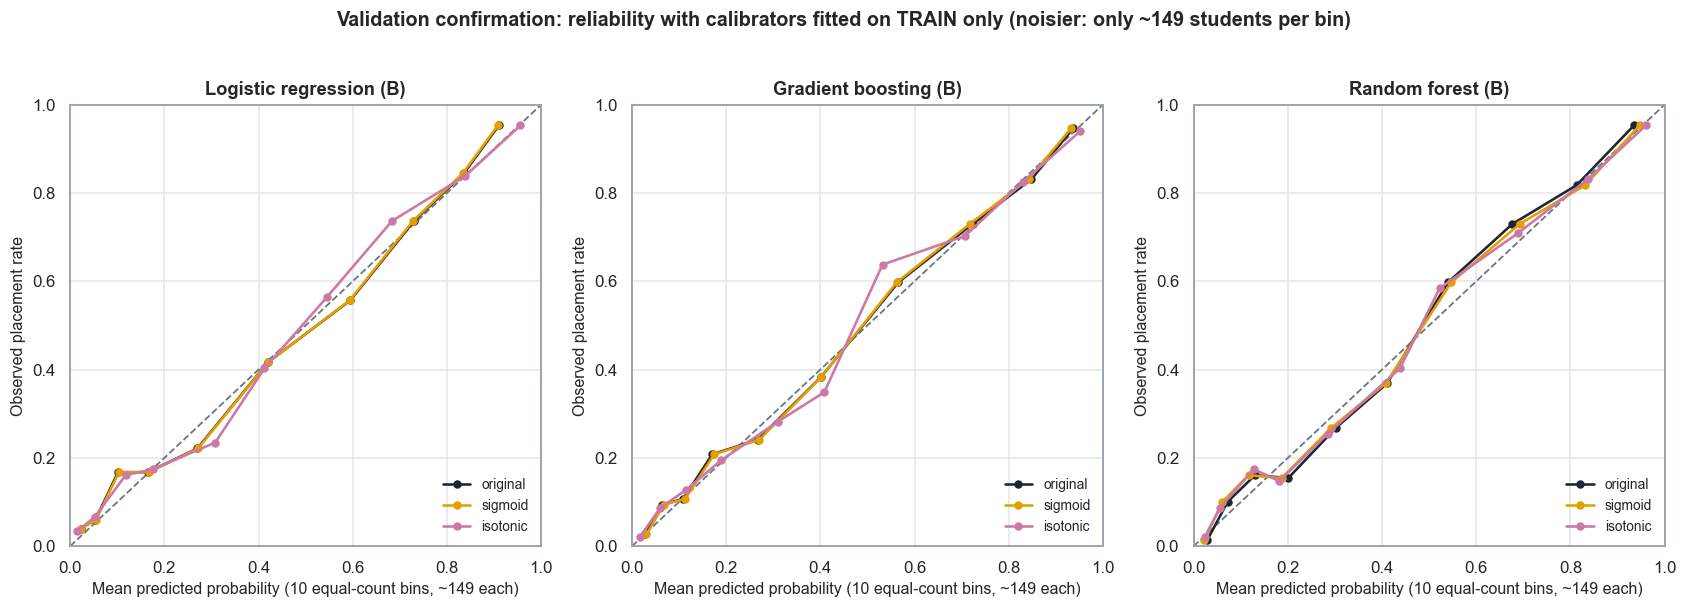

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.4))
for ax, m in zip(axes, MODEL_IDS):
    ax.plot([0, 1], [0, 1], color=NEUTRAL, ls="--", lw=1.2)
    for meth in ["original", "sigmoid", "isotonic"]:
        b = quantile_bins(VAL[m][meth], y_va); ax.plot(b.mean_pred, b.obs_rate, "o-", color=METH_C[meth], lw=1.7, ms=4.5, label=meth)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_title(LABEL[m]); ax.set_xlabel("Mean predicted probability (10 equal-count bins, ~149 each)"); ax.set_ylabel("Observed placement rate"); ax.legend(frameon=False, loc="lower right", fontsize=9)
fig.suptitle("Validation confirmation: reliability with calibrators fitted on TRAIN only (noisier: only ~149 students per bin)", y=1.02, fontsize=13, fontweight="semibold")
savefig(fig, "phase5_validation_reliability")
pd.DataFrame({"train_row_id": train_row_id, "actual_target": y_tr, **{f"{m}_{meth}": CAL[m][meth] for m in MODEL_IDS for meth in ("sigmoid", "isotonic")}, "fold": fold_of}).to_csv(MET / "06_oof_recalibrated_predictions.csv", index=False)

## 9. Part 10: How to read a predicted probability
A predicted probability of 0.80 should **not** be read as "this particular student has an 80% chance of being placed". A reasonable calibrated model supports the weaker, population-level statement: **among students who receive predicted probabilities around 0.80 (and are similar to the students in this dataset), roughly 80% are expected to be placed.**
That is exactly what a reliability diagram checks. The probability summarises a *group* of students with similar profiles; any individual either is or is not placed, and the model uses only ten recorded variables and observational data from one (possibly rule-generated) dataset, so these probabilities describe association, not what would happen if a student changed any characteristic. Calibration quality also does not transfer automatically to other campuses or years.

## 10. Phase 5 conclusions

> **Evidence labels.** *Train CV* = 5-fold cross-validation on the training set only (n = 6,938). *Nested* = out-of-sample recalibration, calibrators fitted only on data that excludes the evaluated student. *Validation confirmation* = one evaluation on the validation set (n = 1,487) with calibrators fitted on train only. **`test.csv` was never opened** (a hook raises an error on any attempt; the audit above lists every data file read). Associations only; no causal claims. Hyper-parameters for GB and RF were chosen on the validation split in Phase 4, so train-CV estimates for those two are not fully independent of validation.

### Model stability: is the Phase 4 tie real?
| 5-fold CV on TRAIN (mean +/- SD across folds) | ROC-AUC | Log loss | Brier | F1 (secondary) |
|---|---|---|---|---|
| Logistic regression (B) | 0.879 +/- 0.010 | 0.431 +/- 0.016 | 0.139 +/- 0.006 | 0.756 |
| Gradient boosting (B) | 0.876 +/- 0.011 | 0.434 +/- 0.020 | 0.141 +/- 0.008 | 0.750 |
| Random forest (B) | 0.876 +/- 0.010 | 0.433 +/- 0.015 | 0.140 +/- 0.006 | 0.746 |

- **Cross-validation supports the Phase 4 conclusion: the three models are practically tied.** The gap between the best and worst fold-mean is only about 0.2-0.3 of the typical fold-to-fold standard deviation for every primary metric (AUC 0.003 vs SD 0.010; log loss 0.004 vs 0.017; Brier 0.001 vs 0.006).
- Logistic regression has the best mean on all three primary metrics, but the margins are tiny. Paired fold differences (LR minus other; negative is better for log loss/Brier): vs GB, AUC +0.003 (LR higher in 5/5 folds), log loss -0.004 (4/5), Brier -0.001 (3/5); vs RF, AUC +0.003 (5/5), log loss -0.002 (4/5), Brier -0.001 (4/5). **Every Nadeau-Bengio-corrected 95% interval includes 0** (for example LR-GB log loss -0.011 to +0.004). The uncorrected t-intervals for AUC alone just exclude 0, but they ignore that fold training sets overlap and rest on five folds, so they should not be over-read.
- The most that can be said: LR shows a *small, directionally consistent* AUC edge (all five folds), which is not distinguishable from noise under a conservative interval. Nothing here supports declaring a winner.
- The Phase 4 validation AUC for LR (0.872) lies inside the CV range (0.868-0.890), so the validation split did not look unusually favourable.

### Calibration of the raw probabilities
| Train OOF (out-of-sample) | Slope (95% CI) | Calibration-in-the-large | ECE (10 equal-count bins) | ECE if perfectly calibrated (mean / 95th pct) |
|---|---|---|---|---|
| Logistic regression | 0.99 (0.95-1.03) | -0.000 | 0.021 | 0.011 / 0.016 |
| Gradient boosting | 0.98 (0.93-1.02) | -0.002 | 0.016 | 0.011 / 0.015 |
| Random forest | **1.08 (1.03-1.13)** | -0.001 | 0.016 | 0.011 / 0.016 |

- **The raw probabilities are already reasonable for all three models.** Average predicted probability equals the observed placement rate (41.6%), and slopes are close to 1.
- **Logistic regression and gradient boosting** have slopes statistically compatible with 1 (neither over- nor under-dispersed). **Random forest** has a slope above 1 (CI excludes 1): its probabilities are slightly *too moderate*, with the top decile predicted 0.934 but observed 0.955 and the second-lowest decile over-predicted (0.067 vs 0.042).
- **Local departures are small but visible.** For logistic regression, the 52-68% range is over-predicted by about 5 percentage points (bin 7: predicted 0.605, observed 0.550), the 21-35% range under-predicted by about 4 points (0.276 vs 0.313), and the top decile under-predicted by about 4 points (0.909 vs 0.949); the lowest decile is over-predicted (0.022 vs 0.014). Gradient boosting shows the same pockets (0.583 vs 0.550; 0.270 vs 0.314). Several of these (LR bins 5, 7 and 10) lie just outside the single-bin 95% interval, which is consistent with LR's ECE slightly exceeding the noise yardstick, but the departures are small in absolute terms (at most about 5-6 points).
- **ECE, read against its noise yardstick:** logistic regression's training-OOF ECE (0.021) is modestly above what sampling noise alone would give for perfect calibration (95th percentile 0.016), whereas GB and RF are at the boundary. On the **validation** set, **all ECEs fall inside the noise range** (for example LR 0.024 vs null 95th percentile 0.034). So miscalibration is small and only weakly detectable; ECE is supplementary and bin-dependent.

### Does recalibration help? (nested train analysis, then validation confirmation)
| Change vs original | LR log loss | GB log loss | RF log loss | AUC change |
|---|---|---|---|---|
| Sigmoid, train nested | -0.0000 (CI -0.0001, +0.0001) | -0.0000 (-0.0004, +0.0003) | -0.0006 (-0.0015, +0.0002) | about 0 |
| Isotonic, train nested | -0.0008 (-0.0034, +0.0018) | +0.0015 (-0.0008, +0.0037) | **+0.0029 (+0.0006, +0.0052), worse** | -0.0015 to -0.0017 |
| Sigmoid, validation | -0.0000 | -0.0001 | -0.0005 | about 0 |
| Isotonic, validation | +0.0012 | +0.0015 | +0.0031 | -0.0006 to -0.0011 |

- **Sigmoid (Platt) calibration changes almost nothing.** It moves slopes to 1.00 by construction but log loss and Brier move by at most 0.0006, with intervals including 0, and it improves log loss in only 2-3 of 5 folds. The effect is **negligible**.
- **Isotonic calibration does not help.** It lowers ECE (about 0.009 for all three), but ECE is the most binning-sensitive measure, whereas log loss and Brier are unchanged or *worse* (significantly worse for random forest). It also lowers AUC slightly (about 0.0015) because it collapses predictions into about 215-240 distinct values (ties), and it assigns the clipped extreme probabilities 0.001/0.999 to 0.8-2.5% of students, which is over-confident at the extremes. With about 5,500 calibration points per model it adds many parameters for no measurable gain.
- **No method met the pre-declared materiality rule** (log-loss gain of at least 0.005 with an interval below zero) for any model, on train or validation. Sigmoid cannot repair the logistic regression's small local wiggles because they are not logistic-shaped, and isotonic's flexibility costs as much variance as it removes bias.

### Where the probabilities sit, and whether confidence is justified (train OOF; `06_probability_distribution_summary.csv`)
| Original probabilities | Min / max | Quantiles 5 / 25 / 50 / 75 / 95% | Below 0.2 | 0.2-0.8 | Above 0.8 | Observed placed rate: below 0.2 / above 0.8 |
|---|---|---|---|---|---|---|
| Logistic regression | 0.005 / 0.949 | 0.022 / 0.097 / 0.349 / 0.748 / 0.909 | 38.9% | 40.2% | 20.8% | 8.4% (mean predicted 8.0%) / 89.5% (87.7%) |
| Gradient boosting | 0.008 / 0.976 | 0.029 / 0.103 / 0.337 / 0.738 / 0.935 | 39.1% | 40.6% | 20.3% | 9.0% (8.7%) / 89.0% (89.5%) |
| Random forest | 0.006 / 0.979 | 0.027 / 0.119 / 0.361 / 0.692 / 0.935 | 34.8% | 47.8% | 17.3% | 7.7% (8.6%) / 91.1% (89.7%) |

- **Most students receive a confident probability.** About 60% (LR, GB) to 52% (RF) fall below 0.2 or above 0.8, but no model assigns anything beyond about 0.005 or 0.98 (minimum 0.005-0.008, maximum 0.95-0.98). Random forest places more students in the uncertain 0.2-0.8 middle (47.8% vs about 40%): it is the most hedged of the three, consistent with its slope above 1.
- **Extremes are justified here, but by the reliability evidence, not by their extremity.** In the bands below 0.2 and above 0.8, the observed placement rate is within about 2 percentage points of the mean predicted probability for all three models. A probability of 0.9 is therefore not an over-claim in this dataset. That is a statement about calibration, not about discrimination: confident predictions can still be wrong for individual students (roughly 1 in 10 students above 0.8 is not placed, and about 1 in 12 below 0.2 is placed).
- **The uncertain middle is genuinely uncertain.** Students predicted 0.2-0.8 are placed about 48-49% of the time under every model, so this band carries little more than coin-flip information; this is where the overlap between the Placed and NotPlaced distributions seen in Phase 4 lives.
- No model produces the coarse probability levels of the Phase 4 decision tree, and none produces 0/1 extremes.

### Probability quality: which candidate is most defensible?
- All three produce acceptably calibrated probabilities; none needs recalibration to be usable.
- **Logistic regression** has the best mean log loss, Brier and AUC in CV, a calibration slope of 0.99, the smallest train-validation gap in Phase 4, and directly interpretable coefficients. It is the most defensible *provisional* candidate, not a proven superior one.
- Gradient boosting is equally well calibrated and statistically tied, but offers no probability-quality advantage that would justify opacity. Random forest is slightly under-dispersed (slope 1.08) and had the largest train-validation gap in Phase 4.
- **Systematic regions:** modest over-prediction in the mid-to-upper range (about 52-68%) and under-prediction at the highest (> 0.9) and 21-35% ranges for LR/GB; at the extremes the RF is too timid. These are at most about 5-6 points and partly within sampling noise.

### Provisional model
- **Logistic regression with categorical counts (LR_B) remains the provisionally preferred model.** Phase 5 gives no evidence to replace it, and cross-validation supports the earlier tie, so the choice rests on interpretability and consistency rather than on a demonstrated accuracy advantage.
- **Calibration need not be part of the final pipeline**: the raw LR probabilities are acceptably calibrated, and sigmoid/isotonic add complexity without measurable benefit. If a final pipeline later includes any calibration step it should be sigmoid, not isotonic, but this phase does not recommend it.
- No final model is declared. The test set remains reserved for one-time evaluation.

### What a predicted probability means (for the report and viva)
A predicted probability of 0.80 does **not** mean that this particular student has an 80% chance of being placed. It supports the group-level statement: *among students who receive predicted probabilities around 0.80, and who resemble the students in this dataset, roughly 80% are expected to be placed.* The reliability diagrams check exactly this, and the statement holds only approximately (within a few percentage points in the mid-to-upper range). The model uses ten recorded variables from one, possibly rule-generated, campus dataset and describes association, not what would happen if a student changed a characteristic.

### Limitations
- Five folds give coarse stability estimates; fold training sets overlap, and the bootstrap intervals for recalibration treat pooled OOF predictions as independent, so they understate uncertainty slightly.
- OOF/CV models are trained on 80% of the training data; the final models use 100%. Calibrators fitted on OOF probabilities and applied to full-train models carry this small mismatch.
- ECE and reliability bins depend on the binning (10 equal-count bins here); ECE should be read with its noise yardstick.
- Validation (n = 1,487, about 149 per bin) cannot detect small miscalibration; its CITL interval (about +/-0.14 on the log-odds scale) is wide.
- GB/RF hyper-parameters were selected on validation in Phase 4; results describe one dataset and need not transfer to other institutions.

### Recommendation for Phase 6
1. **Freeze the pipeline before touching the test set:** LR_B (Phase 4 pipeline, C = 1, categorical counts), raw probabilities, **no recalibration**, fitted on the **training set only** (the exact artifact that was selected and validated; refitting a 16-parameter model on 21% more data is expected to change little).
2. **Pre-register the evaluation:** one pass over `test.csv` reporting ROC-AUC, log loss, Brier, calibration slope/CITL, a reliability diagram with Wilson intervals and its ECE noise yardstick, and bootstrap intervals; GB_B and RF_B may be reported as pre-declared secondary comparators with **no re-selection** based on the outcome.
3. **Decide any classification threshold before Phase 6** from train OOF or validation predictions (the default 0.5 is acceptable if no cost trade-off is stated); do not tune on test.
4. **Interpretation work** (permutation importance/SHAP, coefficient stability) can be done on train/validation before or alongside the final evaluation, but must not influence model choice after the test is seen.

## 11. Test-set audit

In [21]:
data_ext = (".csv", ".parquet", ".json", ".joblib", ".pkl", ".feather", ".xlsx")
opened = sorted({os.path.normpath(p) for p in _OPENED if p.lower().endswith(data_ext)})
print("Data files opened during this notebook run:")
for p in opened: print("  ", p)
names = [os.path.basename(p).lower() for p in opened]
assert "test.csv" not in names, "test.csv (processed or raw) was opened!"
assert not any(("raw" in Path(p).parts and "data" in Path(p).parts) for p in opened), "a raw data file was opened"
assert "modeling_dataset.csv" not in names and "campus_recruitment_combined_flagged.csv" not in names
assert {"train.csv", "validation.csv"} <= set(names)
assert "X_test" not in globals() and "y_test" not in globals() and "test" not in globals()
print("\nASSERTIONS PASSED: test.csv (raw or processed) was never opened. CV, OOF predictions and calibration used TRAIN only; validation was used once for confirmation.")

Data files opened during this notebook run:
   C:\Users\Aryan\.matplotlib\fontlist-v390.json
   C:\Users\Aryan\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy-2.4.2.dist-info\direct_url.json
   D:\Student-Placement-Prediction\student-placement-prediction\data\processed\train.csv
   D:\Student-Placement-Prediction\student-placement-prediction\data\processed\validation.csv
   D:\Student-Placement-Prediction\student-placement-prediction\models\phase4\GB_B.joblib
   D:\Student-Placement-Prediction\student-placement-prediction\models\phase4\LR_B.joblib
   D:\Student-Placement-Prediction\student-placement-prediction\models\phase4\RF_B.joblib
   D:\Student-Placement-Prediction\student-placement-prediction\models\phase4\model_configs.json
   D:\Student-Placement-Prediction\student-placement-prediction\results\metrics\modeling\05_provisional_selection.json
   D:\Student-Placement-Prediction\student-placement-prediction\results\metrics\modeling\05_validation_predictions.csv
   D: